# 🫁 Chest X-Ray Screening Assistant with Explainability
### Multi-Class Classification (Normal, Pneumonia, Tuberculosis) with Grad-CAM & Calibration

**Project Objective:**
- Flag likely **Pneumonia** or **Tuberculosis** in chest X-rays to support (not replace) clinicians.
- Show **WHERE** the model looked using **Grad-CAM heatmaps** overlaid on the original X-ray.
- Provide **calibrated confidence** and uncertainty metrics.
- Automatically save and load the trained model from **Google Drive** so training is not repeated if the session disconnects.


In [1]:
# ==============================================================================
# Cell 1: Mount Google Drive & Environment Setup
# ==============================================================================
import os

# 1. Mount Google Drive so model weights are saved permanently
try:
    from google.colab import drive
    drive.mount('/content/drive')
    MODEL_SAVE_PATH = '/content/drive/MyDrive/chest_xray_densenet.pth'
    print("✅ Google Drive mounted successfully.")
except Exception:
    MODEL_SAVE_PATH = 'chest_xray_densenet.pth'
    print("ℹ️ Running in local/offline environment without Colab Drive mount.")

print(f"📁 Trained model checkpoint path: {MODEL_SAVE_PATH}")

# 2. Install dependencies (kagglehub for direct dataset linking, timm, opencv)
!pip install -q kagglehub opencv-python seaborn scikit-learn

import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

# Set seed for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Check GPU acceleration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Execution device: {device}")


Mounted at /content/drive
✅ Google Drive mounted successfully.
📁 Trained model checkpoint path: /content/drive/MyDrive/chest_xray_densenet.pth
🚀 Execution device: cuda


In [8]:

# ==============================================================================
# Cell 2: Clean and Balanced Dataset — 2,100 Images
# ==============================================================================

import os
import random
import hashlib
import pandas as pd
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)

CLASS_NAMES = ["Normal", "Pneumonia", "Tuberculosis"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

SAMPLES_PER_CLASS = 700
NORMAL_PER_SOURCE = 350

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

print("Accessing Kaggle datasets...")

tb_path = kagglehub.dataset_download(
    "tawsifurrahman/tuberculosis-tb-chest-xray-dataset"
)

pneu_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)


def collect_images(root, folder_names):
    """Collect only readable images from exact class folders."""

    valid_files = []

    for current_root, dirs, filenames in os.walk(root):

        # Ignore macOS metadata directories
        dirs[:] = [
            d for d in dirs
            if d != "__MACOSX" and not d.startswith(".")
        ]

        folder_name = os.path.basename(
            os.path.normpath(current_root)
        ).lower()

        if folder_name not in folder_names:
            continue

        for filename in filenames:

            # Ignore hidden files and macOS resource-fork files
            if filename.startswith(".") or filename.startswith("._"):
                continue

            extension = os.path.splitext(filename)[1].lower()

            if extension not in IMAGE_EXTENSIONS:
                continue

            filepath = os.path.abspath(
                os.path.join(current_root, filename)
            )

            # Verify the image can actually be opened
            try:
                with Image.open(filepath) as img:
                    img.verify()

                valid_files.append(filepath)

            except Exception:
                print("Skipping unreadable image:", filepath)

    return sorted(set(valid_files))


def get_file_hash(filepath):
    """Calculate SHA256 to identify exact duplicate image files."""

    digest = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


print("\nScanning image folders...")

pneumonia_files = collect_images(
    pneu_path, {"pneumonia"}
)

tb_files = collect_images(
    tb_path, {"tuberculosis", "tb"}
)

normal_pneu_files = collect_images(
    pneu_path, {"normal"}
)

normal_tb_files = collect_images(
    tb_path, {"normal"}
)

print("\nReadable images found:")
print("Pneumonia:", len(pneumonia_files))
print("Tuberculosis:", len(tb_files))
print("Normal from Pneumonia dataset:", len(normal_pneu_files))
print("Normal from TB dataset:", len(normal_tb_files))


# Remove exact duplicate Normal images across both datasets
print("\nChecking Normal images for exact duplicates...")

normal_seen_hashes = set()

def remove_exact_duplicates(files, seen_hashes):
    unique_files = []

    for filepath in files:
        digest = get_file_hash(filepath)

        if digest not in seen_hashes:
            seen_hashes.add(digest)
            unique_files.append(filepath)

    return unique_files


normal_pneu_files = remove_exact_duplicates(
    normal_pneu_files, normal_seen_hashes
)

normal_tb_files = remove_exact_duplicates(
    normal_tb_files, normal_seen_hashes
)

print("Unique Normal images from Pneumonia dataset:",
      len(normal_pneu_files))
print("Unique Normal images from TB dataset:",
      len(normal_tb_files))


# Validate image availability
if len(pneumonia_files) < 700:
    raise ValueError(
        f"Only {len(pneumonia_files)} readable Pneumonia images found."
    )

if len(tb_files) < 700:
    raise ValueError(
        f"Only {len(tb_files)} readable Tuberculosis images found."
    )

if len(normal_pneu_files) < NORMAL_PER_SOURCE:
    raise ValueError(
        "Not enough unique Normal images in Pneumonia dataset."
    )

if len(normal_tb_files) < NORMAL_PER_SOURCE:
    raise ValueError(
        "Not enough unique Normal images in TB dataset."
    )


# Reproducible sampling
rng = random.Random(SEED)

selected_pneumonia = rng.sample(pneumonia_files, 700)
selected_tb = rng.sample(tb_files, 700)

selected_normal = (
    rng.sample(normal_pneu_files, NORMAL_PER_SOURCE)
    +
    rng.sample(normal_tb_files, NORMAL_PER_SOURCE)
)


# Build final dataframe
records = []

for filepath in selected_normal:
    records.append({
        "filepath": filepath,
        "label": "Normal",
        "target": CLASS_TO_IDX["Normal"]
    })

for filepath in selected_pneumonia:
    records.append({
        "filepath": filepath,
        "label": "Pneumonia",
        "target": CLASS_TO_IDX["Pneumonia"]
    })

for filepath in selected_tb:
    records.append({
        "filepath": filepath,
        "label": "Tuberculosis",
        "target": CLASS_TO_IDX["Tuberculosis"]
    })


df = pd.DataFrame(records)

df = df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Dataset integrity checks
assert len(df) == 2100
assert df["filepath"].is_unique

for class_name in CLASS_NAMES:
    assert (df["label"] == class_name).sum() == 700


print("\n" + "=" * 60)
print("FINAL CLEAN DATASET")
print("=" * 60)

print("Total images:", len(df))
print(df["label"].value_counts().reindex(CLASS_NAMES))


# Stratified 70:15:15 split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["target"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["target"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


print("\n" + "=" * 60)
print("STRATIFIED DATASET SPLIT")
print("=" * 60)

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{split_name}: {len(split_df)} images")
    print(
        split_df["label"]
        .value_counts()
        .reindex(CLASS_NAMES)
    )

print("\nDataset preparation completed successfully.")


Accessing Kaggle datasets...
Using Colab cache for faster access to the 'tuberculosis-tb-chest-xray-dataset' dataset.
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.

Scanning image folders...

Readable images found:
Pneumonia: 8546
Tuberculosis: 700
Normal from Pneumonia dataset: 3166
Normal from TB dataset: 3500

Checking Normal images for exact duplicates...
Unique Normal images from Pneumonia dataset: 1579
Unique Normal images from TB dataset: 3500

FINAL CLEAN DATASET
Total images: 2100
label
Normal          700
Pneumonia       700
Tuberculosis    700
Name: count, dtype: int64

STRATIFIED DATASET SPLIT

Training: 1470 images
label
Normal          490
Pneumonia       490
Tuberculosis    490
Name: count, dtype: int64

Validation: 315 images
label
Normal          105
Pneumonia       105
Tuberculosis    105
Name: count, dtype: int64

Testing: 315 images
label
Normal          105
Pneumonia       105
Tuberculosis    105
Name: count, dtype: int64

Dataset prepa

In [9]:

# ==============================================================================
# Cell 3: Data Augmentation, Dataset and DataLoaders
# ==============================================================================

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Training augmentations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing: no random augmentation
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class XRayDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        filepath = row["filepath"]

        try:
            with Image.open(filepath) as img:
                image = img.convert("RGB")

            label = int(row["target"])

            if self.transform:
                image = self.transform(image)

            return image, label, filepath

        except Exception as e:
            raise RuntimeError(
                f"Could not load image at index {idx}: {filepath}\n"
                f"Original error: {e}"
            ) from e


# Create datasets
train_dataset = XRayDataset(
    train_df,
    transform=train_transforms
)

val_dataset = XRayDataset(
    val_df,
    transform=val_transforms
)

test_dataset = XRayDataset(
    test_df,
    transform=val_transforms
)


# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# Class weights
class_counts = (
    train_df["target"]
    .value_counts()
    .sort_index()
    .values
)

class_weights = (
    len(train_df) /
    (len(CLASS_NAMES) * class_counts.astype(np.float32))
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)


# Verify one batch before training
sample_images, sample_labels, sample_paths = next(iter(train_loader))

print("DataLoaders created successfully.")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Batch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)
print("Class weights:", class_weights)

assert sample_images.shape[1:] == (3, 224, 224)
assert len(train_dataset) == 1470
assert len(val_dataset) == 315
assert len(test_dataset) == 315

print("\nData pipeline verification passed.")


DataLoaders created successfully.
Training images: 1470
Validation images: 315
Testing images: 315
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Class weights: [1. 1. 1.]

Data pipeline verification passed.


##**Visualize Augmentation**

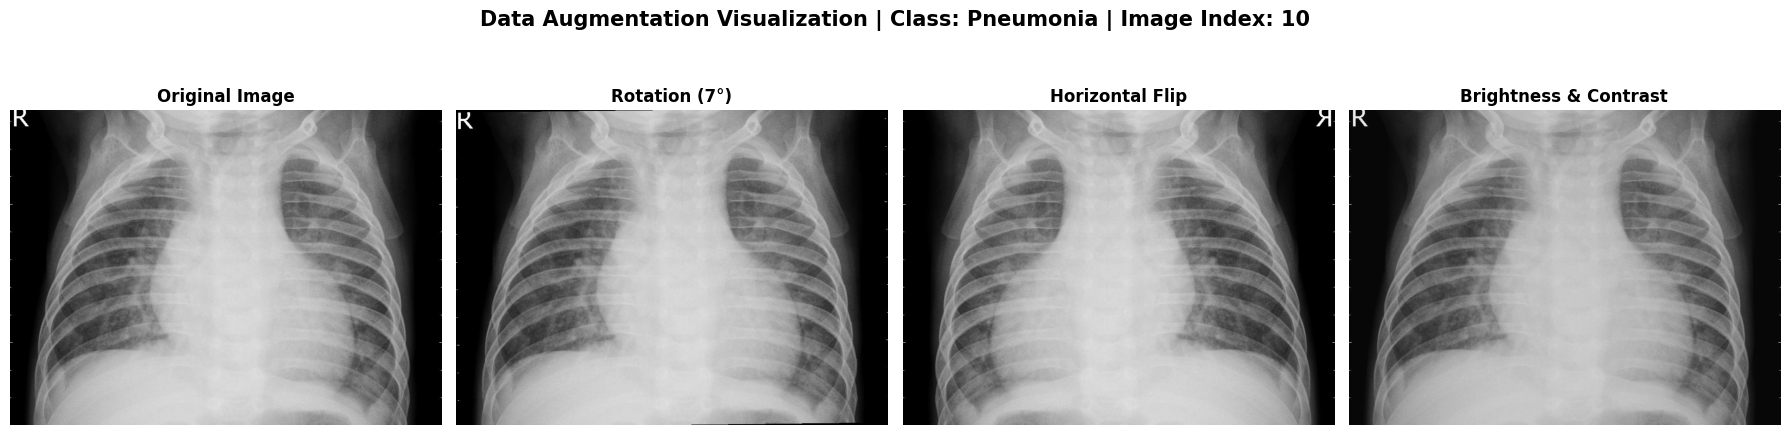

Original Image: /kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA/person1646_bacteria_4368.jpeg
Displayed: Original + Rotation + Horizontal Flip + Brightness/Contrast


In [10]:

# ==============================================================================
# Cell 3.1: Visualizing Original Image vs Data Augmentations
# ==============================================================================

# Select a FIXED image (not random)
IMAGE_INDEX = 10

# Get original image from training dataframe
image_path = train_df.iloc[IMAGE_INDEX]["filepath"]
image_label = train_df.iloc[IMAGE_INDEX]["label"]

original_image = Image.open(image_path).convert("RGB")

# Apply each augmentation individually for visualization
augmented_images = [
    ("Original Image", original_image),
    ("Rotation (7°)", transforms.RandomRotation(degrees=7)(original_image)),
    ("Horizontal Flip", transforms.RandomHorizontalFlip(p=1.0)(original_image)),
    ("Brightness & Contrast", transforms.ColorJitter(
        brightness=0.1, contrast=0.1
    )(original_image))
]

# Display all images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, (title, img) in zip(axes, augmented_images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    f"Data Augmentation Visualization | Class: {image_label} | Image Index: {IMAGE_INDEX}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(f"Original Image: {image_path}")
print("Displayed: Original + Rotation + Horizontal Flip + Brightness/Contrast")


In [11]:

# ==============================================================================
# Cell 4: DenseNet121 vs ResNet50 Model Architectures
# ==============================================================================

def build_densenet121():

    model = models.densenet121(
        weights=models.DenseNet121_Weights.DEFAULT
    )

    num_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.2),
        nn.Linear(num_features, len(CLASS_NAMES))
    )

    return model


def build_resnet50():

    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    num_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(0.2),
        nn.Linear(num_features, len(CLASS_NAMES))
    )

    return model


model_builders = {
    "DenseNet121": build_densenet121,
    "ResNet50": build_resnet50
}

models_dict = {
    name: builder().to(device)
    for name, builder in model_builders.items()
}

EPOCHS = 8
LEARNING_RATE = 1e-4

CHECKPOINT_DIR = (
    "/content/drive/MyDrive"
    if os.path.isdir("/content/drive/MyDrive")
    else "."
)

CHECKPOINT_PATHS = {
    "DenseNet121": os.path.join(
        CHECKPOINT_DIR,
        "chest_xray_densenet121_2100_e8_clean.pth"
    ),
    "ResNet50": os.path.join(
        CHECKPOINT_DIR,
        "chest_xray_resnet50_2100_e8_clean.pth"
    )
}

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

print("Both models initialized successfully.")
print("Device:", device)
print("Training images:", len(train_dataset))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

for name, model_obj in models_dict.items():

    parameter_count = sum(
        p.numel() for p in model_obj.parameters()
    )

    print(f"{name}: {parameter_count:,} parameters")

print("\nCheckpoint paths:")
for name, path in CHECKPOINT_PATHS.items():
    print(name, ":", path)


Both models initialized successfully.
Device: cuda
Training images: 1470
Epochs: 8
Batch size: 32
Learning rate: 0.0001
DenseNet121: 6,956,931 parameters
ResNet50: 23,514,179 parameters

Checkpoint paths:
DenseNet121 : /content/drive/MyDrive/chest_xray_densenet121_2100_e8_clean.pth
ResNet50 : /content/drive/MyDrive/chest_xray_resnet50_2100_e8_clean.pth


In [12]:

# ==============================================================================
# Cell 5: Train or Load Both Models
# ==============================================================================

import copy

histories = {}
trained_models = {}


def train_and_validate(model, model_name, checkpoint_path):

    # Load only a completed checkpoint for this exact experiment
    if os.path.exists(checkpoint_path):

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

        if (
            isinstance(checkpoint, dict)
            and checkpoint.get("completed") is True
            and checkpoint.get("epochs") == EPOCHS
            and checkpoint.get("dataset_size") == len(df)
        ):

            model.load_state_dict(
                checkpoint["best_model_state_dict"]
            )

            print(f"\nLoaded completed checkpoint: {model_name}")

            return model, checkpoint["history"]

        print("\nExisting checkpoint is incomplete or incompatible.")
        print("Starting fresh training for:", model_name)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_acc = -1.0
    best_model_state = copy.deepcopy(model.state_dict())

    print("\n" + "=" * 65)
    print("TRAINING:", model_name)
    print("=" * 65)

    for epoch in range(EPOCHS):

        # ---------------- TRAINING ----------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels, _ in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # ---------------- VALIDATION ----------------
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels, _ in val_loader:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

        # Save best model according to validation accuracy
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            print("Best validation model updated.")

        # Save progress after every epoch
        torch.save({
            "best_model_state_dict": best_model_state,
            "history": history,
            "best_val_acc": best_val_acc,
            "epochs": EPOCHS,
            "dataset_size": len(df),
            "completed": False
        }, checkpoint_path)

    # Restore best validation model
    model.load_state_dict(best_model_state)

    # Save completed checkpoint
    torch.save({
        "best_model_state_dict": best_model_state,
        "history": history,
        "best_val_acc": best_val_acc,
        "epochs": EPOCHS,
        "dataset_size": len(df),
        "completed": True
    }, checkpoint_path)

    print(f"\n{model_name} training completed.")
    print(
        f"Best validation accuracy: "
        f"{best_val_acc * 100:.2f}%"
    )

    return model, history


# Train both architectures
for model_name, model_obj in models_dict.items():

    trained_models[model_name], histories[model_name] = (
        train_and_validate(
            model_obj,
            model_name,
            CHECKPOINT_PATHS[model_name]
        )
    )

print("\nBoth models are ready for evaluation!")



TRAINING: DenseNet121
Epoch [1/8] | Train Loss: 0.3545 | Val Loss: 0.1682 | Train Acc: 86.80% | Val Acc: 92.38%
Best validation model updated.
Epoch [2/8] | Train Loss: 0.1192 | Val Loss: 0.0808 | Train Acc: 96.26% | Val Acc: 97.78%
Best validation model updated.
Epoch [3/8] | Train Loss: 0.0774 | Val Loss: 0.0621 | Train Acc: 97.41% | Val Acc: 97.78%
Epoch [4/8] | Train Loss: 0.0515 | Val Loss: 0.0509 | Train Acc: 98.23% | Val Acc: 98.41%
Best validation model updated.
Epoch [5/8] | Train Loss: 0.0575 | Val Loss: 0.0527 | Train Acc: 98.37% | Val Acc: 98.73%
Best validation model updated.
Epoch [6/8] | Train Loss: 0.0393 | Val Loss: 0.0892 | Train Acc: 98.50% | Val Acc: 96.51%
Epoch [7/8] | Train Loss: 0.0314 | Val Loss: 0.1143 | Train Acc: 99.05% | Val Acc: 96.51%
Epoch [8/8] | Train Loss: 0.0352 | Val Loss: 0.0478 | Train Acc: 98.91% | Val Acc: 98.41%

DenseNet121 training completed.
Best validation accuracy: 98.73%

TRAINING: ResNet50
Epoch [1/8] | Train Loss: 0.5839 | Val Loss: 0.

In [13]:

# ==============================================================================
# Cell 6: Test Evaluation and Calibration – Both Models
# ==============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)


def compute_ece(probs, labels, n_bins=10):

    boundaries = np.linspace(0, 1, n_bins + 1)
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)

    accuracies = predictions == labels
    ece = 0.0

    for i in range(n_bins):

        mask = (
            (confidences > boundaries[i]) &
            (confidences <= boundaries[i + 1])
        )

        if np.sum(mask) > 0:
            ece += (
                abs(
                    np.mean(confidences[mask]) -
                    np.mean(accuracies[mask])
                )
                * np.sum(mask) / len(labels)
            )

    return ece


def get_logits_and_labels(model, loader):

    model.eval()

    logits_list = []
    labels_list = []

    with torch.no_grad():

        for images, labels, _ in loader:

            outputs = model(images.to(device))

            logits_list.append(outputs.cpu())
            labels_list.append(labels.numpy())

    return (
        torch.cat(logits_list),
        np.concatenate(labels_list)
    )


evaluation_results = {}
test_labels_reference = None

for model_name, model_obj in trained_models.items():

    # 1. Fit temperature using validation data only
    val_logits, val_labels = get_logits_and_labels(
        model_obj, val_loader
    )

    temperature = nn.Parameter(torch.ones(1) * 1.5)
    nll = nn.CrossEntropyLoss()

    optimizer_temp = torch.optim.LBFGS(
        [temperature],
        lr=0.01,
        max_iter=50
    )

    val_labels_tensor = torch.tensor(
        val_labels, dtype=torch.long
    )

    def closure():
        optimizer_temp.zero_grad()

        scaled_logits = val_logits / temperature.clamp(min=0.05)

        loss = nll(scaled_logits, val_labels_tensor)
        loss.backward()

        return loss

    optimizer_temp.step(closure)

    optimal_temp = temperature.detach().clamp(
        min=0.05
    ).item()

    # 2. Evaluate on untouched test data
    test_logits, test_labels = get_logits_and_labels(
        model_obj, test_loader
    )

    if test_labels_reference is None:
        test_labels_reference = test_labels

    raw_probs = F.softmax(test_logits, dim=1).numpy()

    calibrated_probs = F.softmax(
        test_logits / optimal_temp,
        dim=1
    ).numpy()

    predictions = np.argmax(calibrated_probs, axis=1)

    # 3. Calculate test metrics
    metrics = {
        "Accuracy": accuracy_score(test_labels, predictions),

        "Precision": precision_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "F1-Score": f1_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "AUROC": roc_auc_score(
            test_labels,
            calibrated_probs,
            multi_class="ovr",
            average="macro"
        ),

        "ECE": compute_ece(
            calibrated_probs,
            test_labels
        )
    }

    evaluation_results[model_name] = {
        "metrics": metrics,
        "predictions": predictions,
        "probabilities": calibrated_probs,
        "raw_probabilities": raw_probs,
        "temperature": optimal_temp,
        "confusion_matrix": confusion_matrix(
            test_labels, predictions
        )
    }

    print(f"\n{'=' * 60}")
    print(f"TEST RESULTS: {model_name}")
    print(f"{'=' * 60}")

    print(f"Validation-fitted temperature: {optimal_temp:.3f}")

    for metric, value in metrics.items():
        print(f"{metric}: {value * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        test_labels,
        predictions,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

print("\nBoth models evaluated successfully.")



TEST RESULTS: DenseNet121
Validation-fitted temperature: 1.151
Accuracy: 96.19%
Precision: 96.39%
Recall: 96.19%
F1-Score: 96.21%
AUROC: 99.82%
ECE: 1.78%

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9115    0.9810    0.9450       105
   Pneumonia     0.9898    0.9238    0.9557       105
Tuberculosis     0.9904    0.9810    0.9856       105

    accuracy                         0.9619       315
   macro avg     0.9639    0.9619    0.9621       315
weighted avg     0.9639    0.9619    0.9621       315


TEST RESULTS: ResNet50
Validation-fitted temperature: 1.321
Accuracy: 97.46%
Precision: 97.51%
Recall: 97.46%
F1-Score: 97.47%
AUROC: 99.85%
ECE: 0.64%

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9450    0.9810    0.9626       105
   Pneumonia     0.9804    0.9524    0.9662       105
Tuberculosis     1.0000    0.9905    0.9952       105

    accuracy                         0.9746 

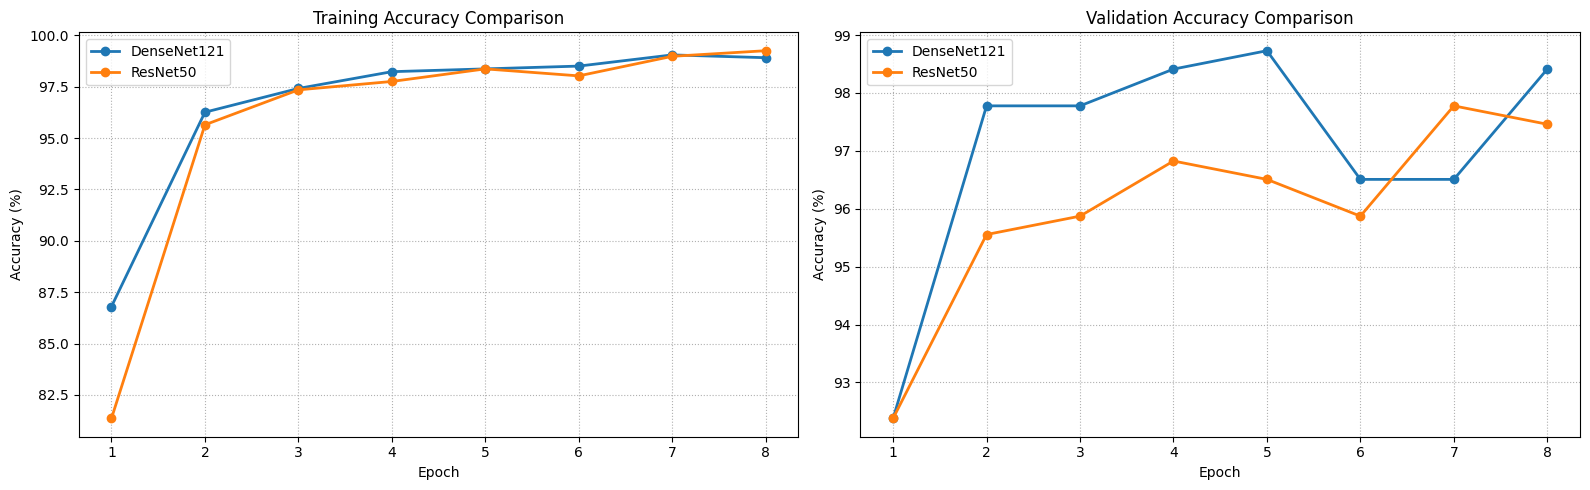

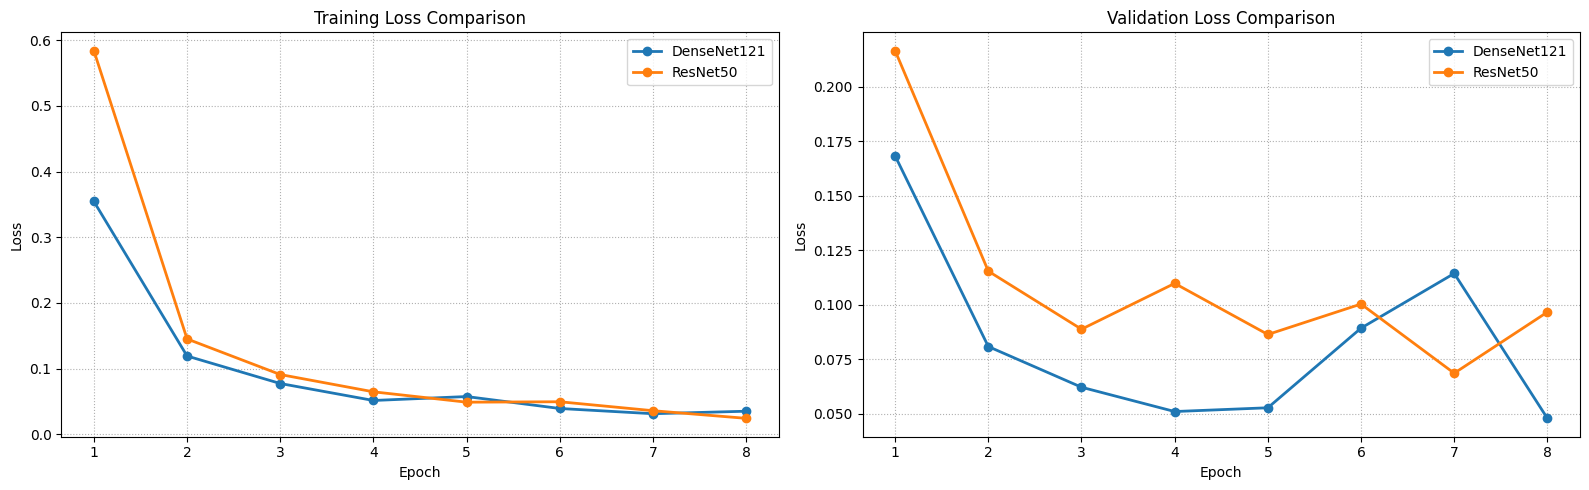

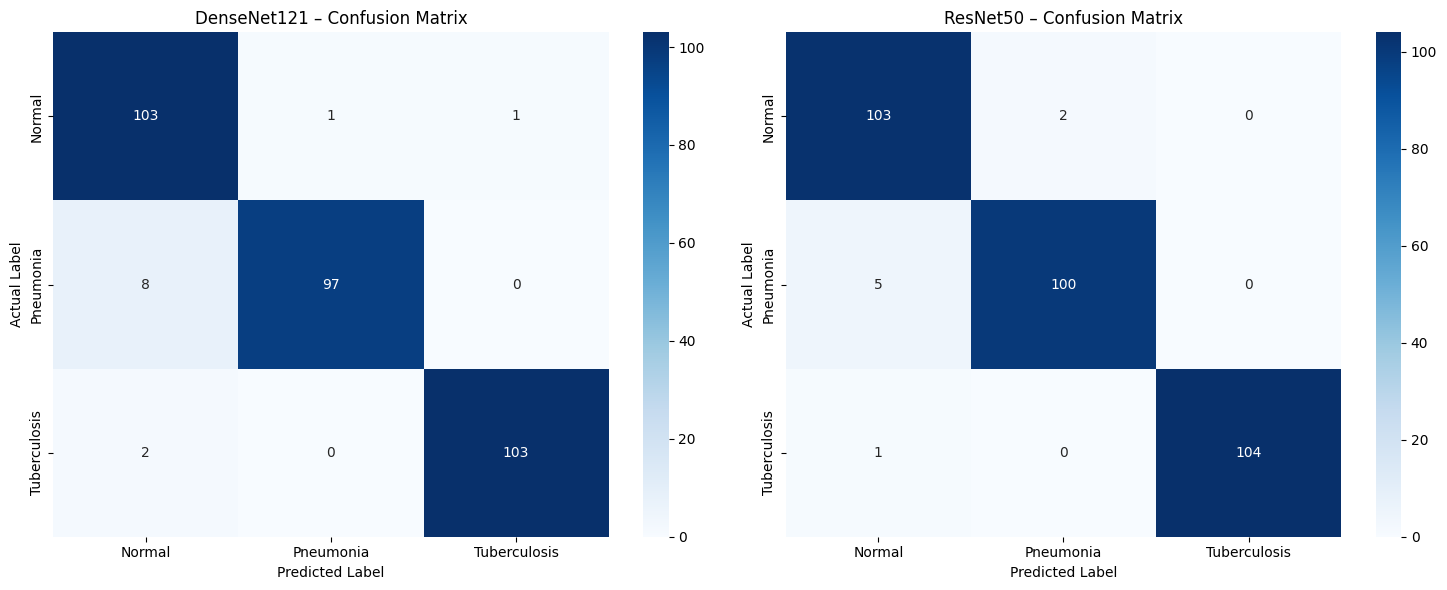

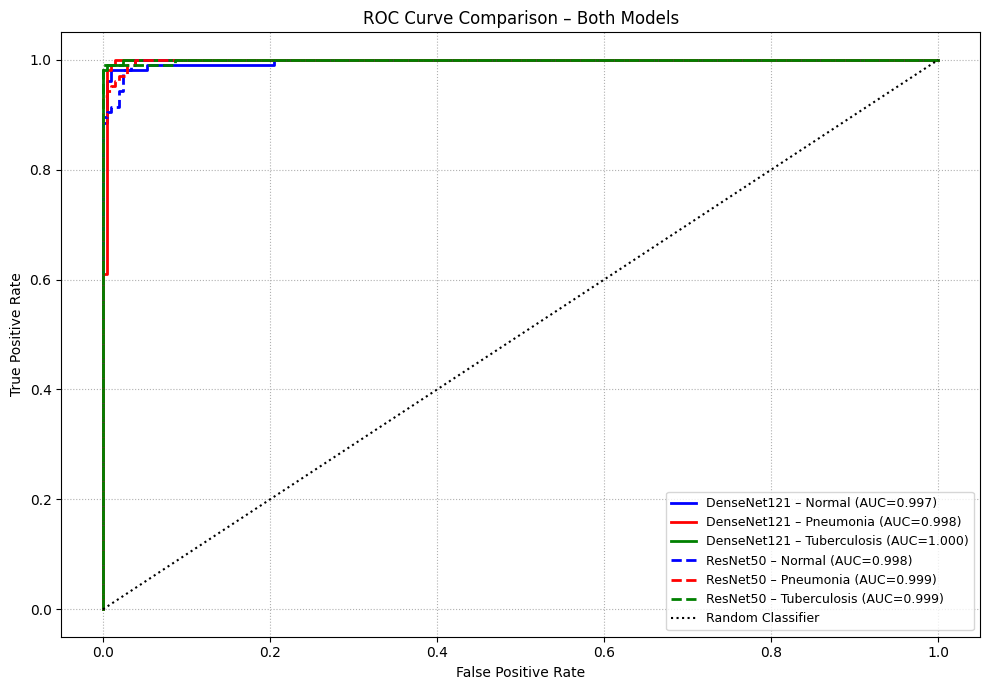

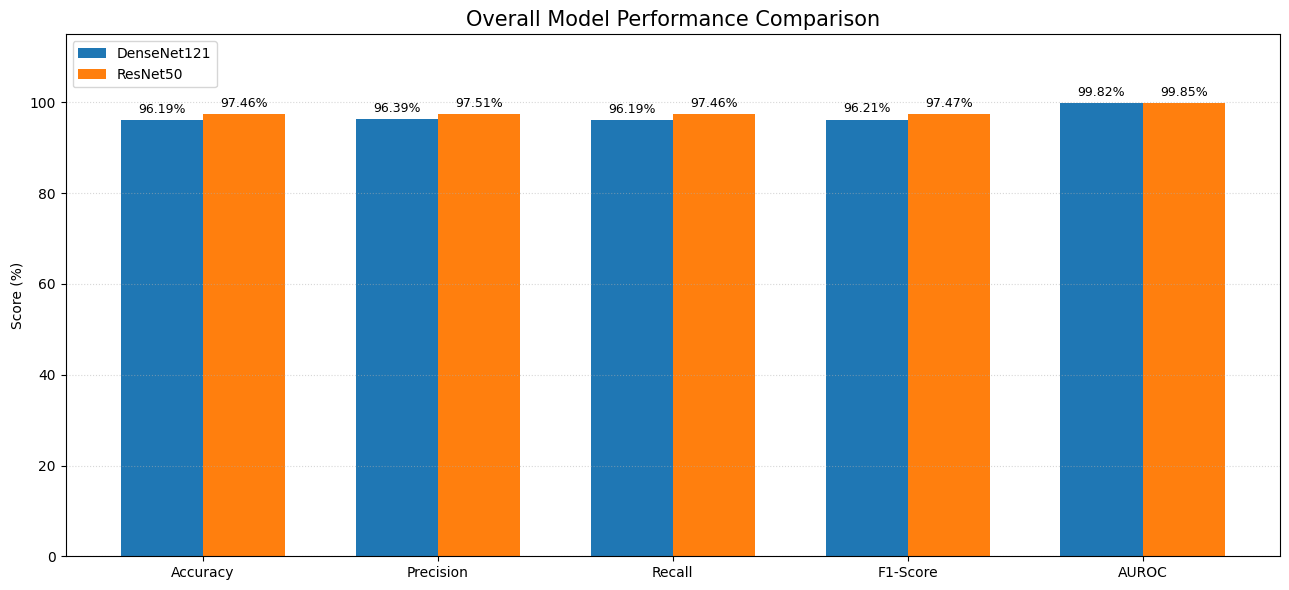

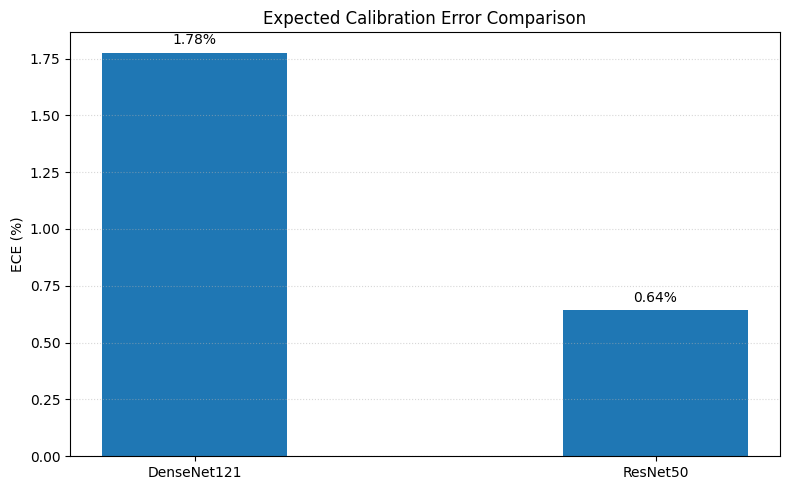


FINAL MODEL COMPARISON


,Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUROC (%),ECE (%)
DenseNet121,96.19,96.39,96.19,96.21,99.82,1.78
ResNet50,97.46,97.51,97.46,97.47,99.85,0.64



Best Model based on Macro F1-Score: ResNet50


In [14]:

# ==============================================================================
# Cell 7: Complete Visual Comparison – DenseNet121 vs ResNet50
# ==============================================================================

from sklearn.preprocessing import label_binarize

MODEL_NAMES = list(trained_models.keys())

# ------------------------------------------------------------------
# 1. Training and Validation Accuracy
# ------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name in MODEL_NAMES:

    h = histories[name]
    epochs = range(1, len(h["train_acc"]) + 1)

    axes[0].plot(
        epochs, np.array(h["train_acc"]) * 100,
        marker="o", linewidth=2, label=name
    )

    axes[1].plot(
        epochs, np.array(h["val_acc"]) * 100,
        marker="o", linewidth=2, label=name
    )

axes[0].set_title("Training Accuracy Comparison")
axes[1].set_title("Validation Accuracy Comparison")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, linestyle=":")
    ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 2. Training and Validation Loss
# ------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name in MODEL_NAMES:

    h = histories[name]
    epochs = range(1, len(h["train_loss"]) + 1)

    axes[0].plot(
        epochs, h["train_loss"],
        marker="o", linewidth=2, label=name
    )

    axes[1].plot(
        epochs, h["val_loss"],
        marker="o", linewidth=2, label=name
    )

axes[0].set_title("Training Loss Comparison")
axes[1].set_title("Validation Loss Comparison")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, linestyle=":")
    ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 3. Confusion Matrices – Both Models
# ------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, name in zip(axes, MODEL_NAMES):

    cm = evaluation_results[name]["confusion_matrix"]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )

    ax.set_title(f"{name} – Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 4. ROC Curve Comparison – Both Models
# ------------------------------------------------------------------

y_test_bin = label_binarize(
    test_labels_reference,
    classes=np.arange(len(CLASS_NAMES))
)

fig, ax = plt.subplots(figsize=(10, 7))

class_colors = ["blue", "red", "green"]
line_styles = ["-", "--"]

for model_idx, name in enumerate(MODEL_NAMES):

    probs = evaluation_results[name]["probabilities"]

    for class_idx, class_name in enumerate(CLASS_NAMES):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, class_idx],
            probs[:, class_idx]
        )

        auc_value = roc_auc_score(
            y_test_bin[:, class_idx],
            probs[:, class_idx]
        )

        ax.plot(
            fpr,
            tpr,
            color=class_colors[class_idx],
            linestyle=line_styles[model_idx],
            linewidth=2,
            label=f"{name} – {class_name} (AUC={auc_value:.3f})"
        )

ax.plot([0, 1], [0, 1], "k:", label="Random Classifier")

ax.set_title("ROC Curve Comparison – Both Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, linestyle=":")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 5. Final Performance Metrics – Comparison Bar Charts
# ------------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUROC"
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))

for i, name in enumerate(MODEL_NAMES):

    values = [
        evaluation_results[name]["metrics"][m] * 100
        for m in metric_names
    ]

    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=name
    )

    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

ax.set_title("Overall Model Performance Comparison", fontsize=15)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 115)
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 6. Calibration Error Comparison (Lower is Better)
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ece_values = [
    evaluation_results[name]["metrics"]["ECE"] * 100
    for name in MODEL_NAMES
]

bars = ax.bar(MODEL_NAMES, ece_values, width=0.4)

ax.bar_label(bars, fmt="%.2f%%", padding=4)

ax.set_title("Expected Calibration Error Comparison")
ax.set_ylabel("ECE (%)")
ax.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------
# 7. Final Numerical Comparison Table
# ------------------------------------------------------------------

comparison_df = pd.DataFrame({
    name: {
        metric: value
        for metric, value in evaluation_results[name]["metrics"].items()
    }
    for name in MODEL_NAMES
}).T

print("\n" + "="*70)
print("FINAL MODEL COMPARISON")
print("="*70)

display((comparison_df * 100).round(2).add_suffix(" (%)"))

# Identify best model by macro F1-score
best_model_name = max(
    MODEL_NAMES,
    key=lambda n: evaluation_results[n]["metrics"]["F1-Score"]
)

print(f"\nBest Model based on Macro F1-Score: {best_model_name}")


Grad-CAM Model: ResNet50


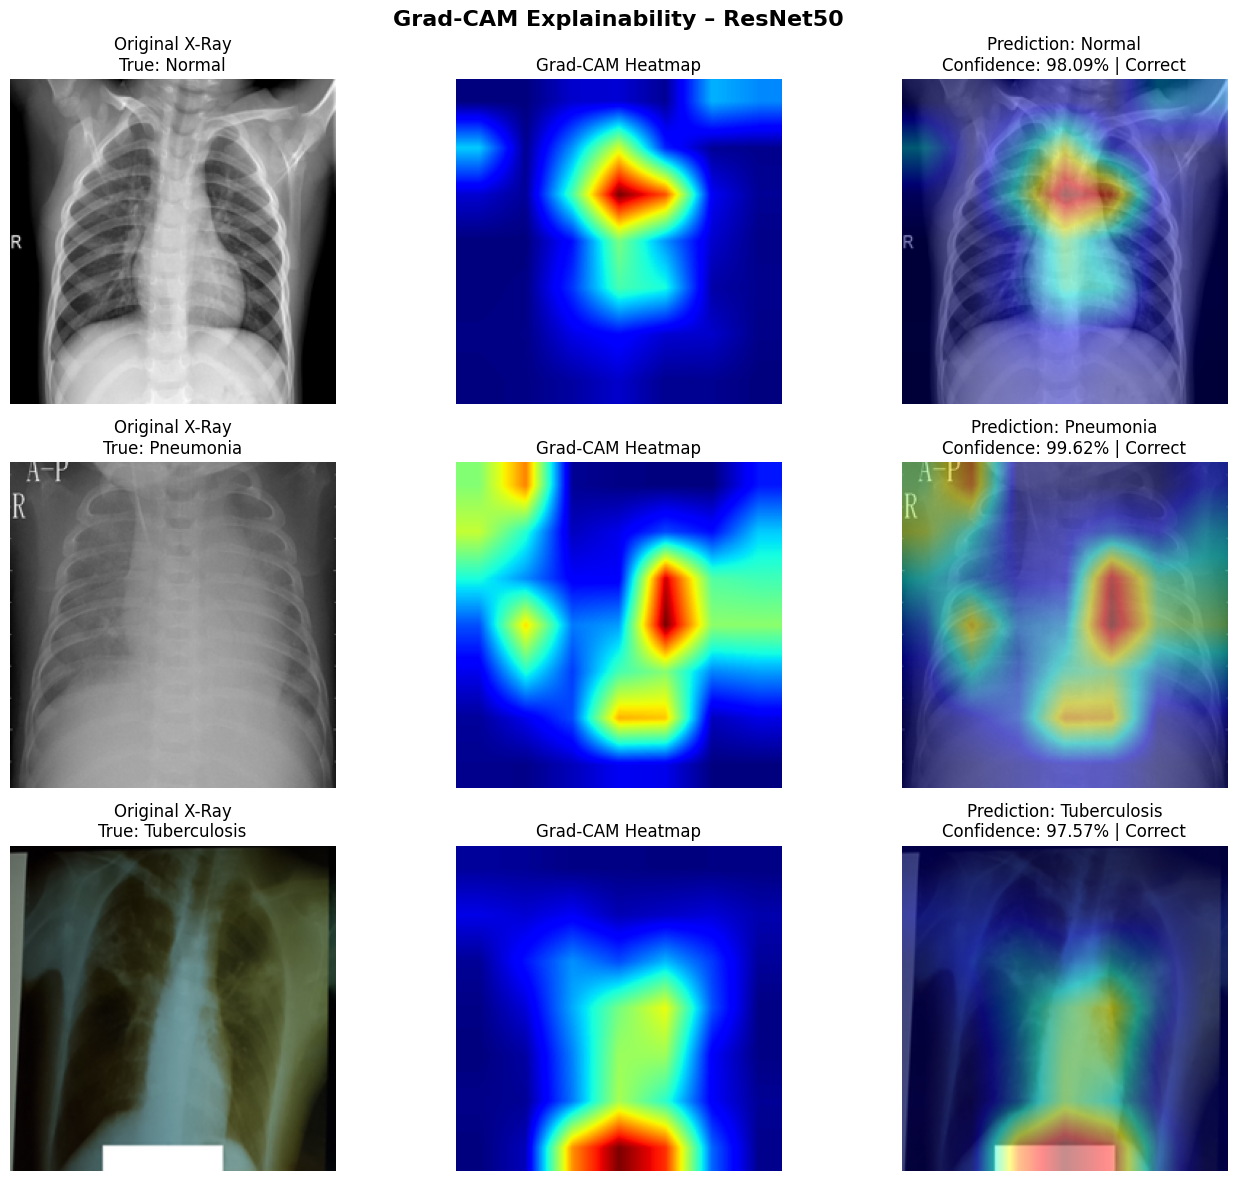

In [15]:

# ==============================================================================
# Cell 8: Grad-CAM Explainability Using the Best Performing Model
# ==============================================================================

# Select best model based on macro F1-score
best_model = trained_models[best_model_name]
best_model.eval()

best_temperature = evaluation_results[best_model_name]["temperature"]

print(f"Grad-CAM Model: {best_model_name}")


class GradCAM:

    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self.forward_hook)
        target_layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, inputs, output):
        self.activations = output.detach()

    def backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor):

        self.model.eval()

        output = self.model(input_tensor)

        predicted_class = output.argmax(dim=1).item()

        self.model.zero_grad()

        output[0, predicted_class].backward()

        weights = torch.mean(
            self.gradients,
            dim=(2, 3),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze().cpu().numpy()

        cam = np.maximum(cam, 0)

        if cam.max() > 0:
            cam = cam / cam.max()

        cam = cv2.resize(cam, (224, 224))

        probabilities = F.softmax(
            output / best_temperature,
            dim=1
        )[0].detach().cpu().numpy()

        return cam, predicted_class, probabilities


# Select correct convolutional layer for the chosen architecture
if best_model_name == "DenseNet121":
    target_layer = best_model.features.denseblock4.denselayer16.conv2

else:
    target_layer = best_model.layer4[-1]

grad_cam = GradCAM(best_model, target_layer)


def make_overlay(pil_img, cam, alpha=0.45):

    img = np.array(
        pil_img.convert("RGB").resize((224, 224))
    )

    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = np.uint8(
        alpha * heatmap + (1 - alpha) * img
    )

    return img, heatmap, overlay


# Display one representative sample from each class
sample_indices = []

for class_idx in range(len(CLASS_NAMES)):

    matches = np.where(
        test_labels_reference == class_idx
    )[0]

    sample_indices.append(int(matches[0]))


fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(14, 12)
)

for row, idx in enumerate(sample_indices):

    img_tensor, true_label, file_path = test_dataset[idx]

    pil_img = Image.open(file_path).convert("RGB")

    cam, predicted_class, probs = grad_cam.generate(
        img_tensor.unsqueeze(0).to(device)
    )

    original, heatmap, overlay = make_overlay(pil_img, cam)

    confidence = probs[predicted_class] * 100

    entropy = -np.sum(
        probs * np.log2(np.clip(probs, 1e-9, 1.0))
    )

    correct = predicted_class == true_label

    status = "Correct" if correct else "Incorrect"

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original X-Ray\nTrue: {CLASS_NAMES[true_label]}"
    )

    axes[row, 1].imshow(cam, cmap="jet")
    axes[row, 1].set_title("Grad-CAM Heatmap")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"Prediction: {CLASS_NAMES[predicted_class]}\n"
        f"Confidence: {confidence:.2f}% | {status}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    f"Grad-CAM Explainability – {best_model_name}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()
